#### Imports

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
pd.set_option('Display.max_columns',None)

#### Loading the data

In [4]:
df = pd.read_csv(r'C:\Users\yurio\OneDrive\Documentos\Google Drive\Carreira Profissional\Projetos Portifólio\Telco_Customer_Churn\data\raw\WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [5]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
df['customerID'].nunique()

7043

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [10]:
for coluna in df:
    print(df[coluna].unique())

<StringArray>
['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW', '9237-HQITU',
 '9305-CDSKC', '1452-KIOVK', '6713-OKOMC', '7892-POOKP', '6388-TABGU',
 ...
 '9767-FFLEM', '0639-TSIQW', '8456-QDAVC', '7750-EYXWZ', '2569-WGERO',
 '6840-RESVB', '2234-XADUH', '4801-JZAZL', '8361-LTMKD', '3186-AJIEK']
Length: 7043, dtype: str
<StringArray>
['Female', 'Male']
Length: 2, dtype: str
[0 1]
<StringArray>
['Yes', 'No']
Length: 2, dtype: str
<StringArray>
['No', 'Yes']
Length: 2, dtype: str
[ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26  0
 39]
<StringArray>
['No', 'Yes']
Length: 2, dtype: str
<StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
<StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
<StringArray>
['Yes', 'No', '

#### EDA

<Axes: xlabel='Churn', ylabel='Count'>

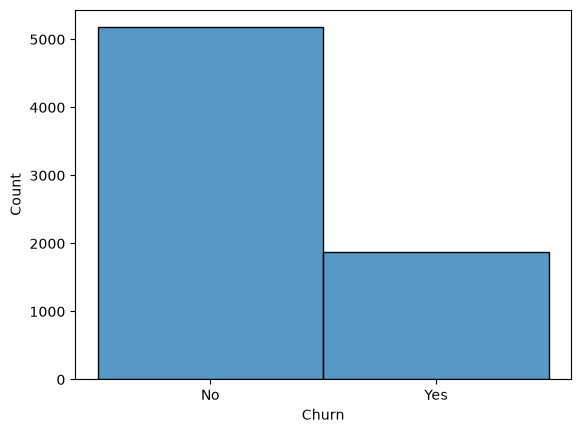

In [11]:
sns.histplot(df['Churn'])

In [12]:
churn = len(df[df['Churn']=='Yes']) / len(df)

<Axes: xlabel='Contract', ylabel='count'>

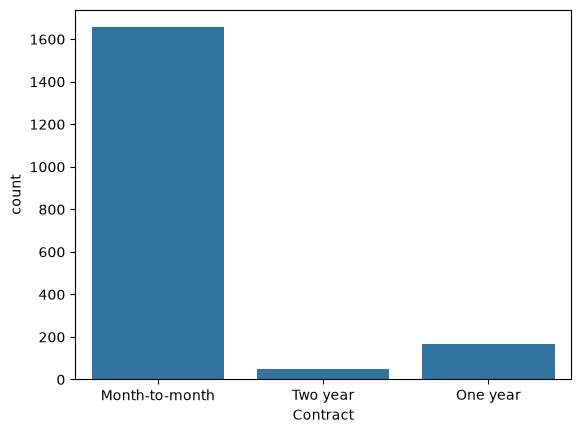

In [13]:
sns.countplot(
    data=df[df['Churn'] == 'Yes'],
    x='Contract'
)

<Axes: xlabel='Contract', ylabel='Churn_Rate'>

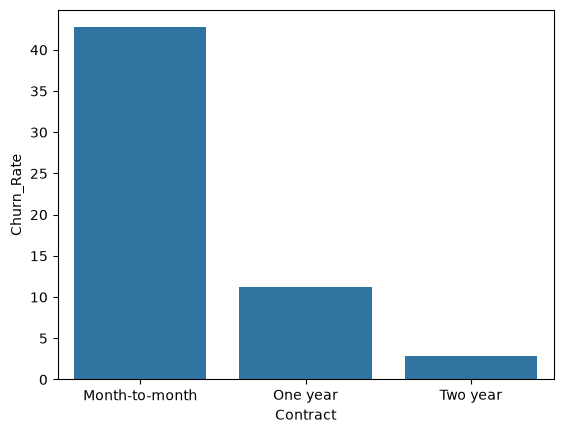

In [14]:
churn_contract = (
    df.groupby('Contract')['Churn']
      .apply(lambda x: (x == 'Yes').mean() * 100)
      .reset_index(name='Churn_Rate')
)

sns.barplot(
    data=churn_contract,
    x='Contract',
    y='Churn_Rate'
)

In [15]:
df['tenure_range'] = pd.cut(
    df['tenure'],
    bins=[0, 12, 24, 36, 48, 60, 72],
    include_lowest=True
)

churn_tenure = (
    df.groupby('tenure_range', observed=False)['Churn']
      .apply(lambda x: (x == 'Yes').mean() * 100)
      .reset_index(name='Churn_Rate')
)

churn_tenure

,tenure_range,Churn_Rate
0,"(-0.001, 12.0]",47.438243
1,"(12.0, 24.0]",28.710938
2,"(24.0, 36.0]",21.634615
3,"(36.0, 48.0]",19.028871
4,"(48.0, 60.0]",14.423077
5,"(60.0, 72.0]",6.609808


Text(0.5, 0, 'Tenure')

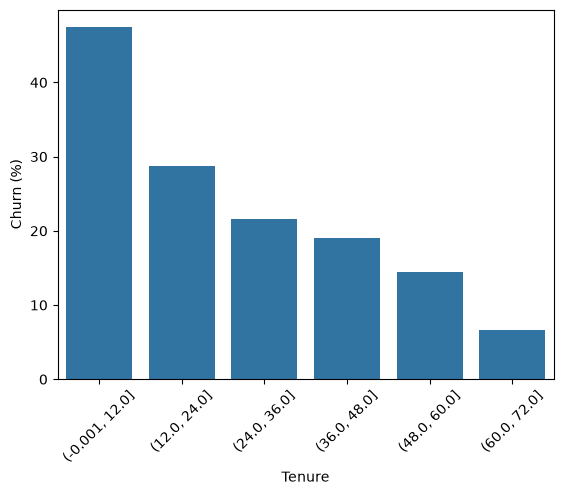

In [16]:
sns.barplot(
    data=churn_tenure,
    x='tenure_range',
    y='Churn_Rate'
)

plt.xticks(rotation=45)
plt.ylabel('Churn (%)')
plt.xlabel('Tenure')

<Axes: xlabel='Churn', ylabel='tenure'>

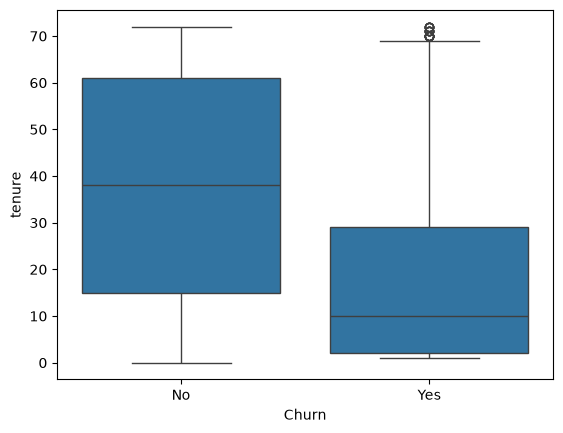

In [17]:
sns.boxplot(
    data=df,
    x='Churn',
    y='tenure'
)

<Axes: xlabel='tenure_range', ylabel='Churn_Rate'>

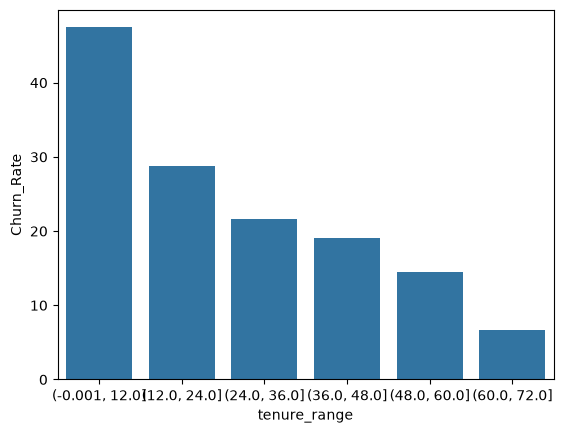

In [18]:
sns.barplot(
    data=churn_tenure,
    x='tenure_range',
    y='Churn_Rate'
)

<Axes: xlabel='Churn', ylabel='MonthlyCharges'>

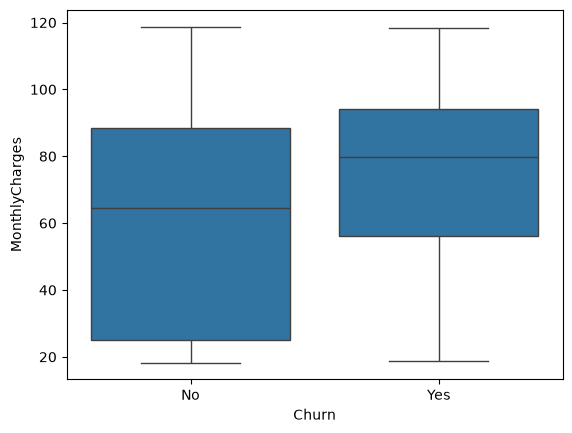

In [19]:
sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges'
)

In [20]:
df['MonthlyCharges_range'] = pd.cut(
    df['MonthlyCharges'],
    bins=5
)

churn_monthly = (
    df.groupby('MonthlyCharges_range', observed=False)['Churn']
      .apply(lambda x: (x == 'Yes').mean() * 100)
      .reset_index(name='Churn_Rate')
)

churn_monthly

,MonthlyCharges_range,Churn_Rate
0,"(18.15, 38.35]",11.407902
1,"(38.35, 58.45]",26.965174
2,"(58.45, 78.55]",29.480614
3,"(78.55, 98.65]",36.966046
4,"(98.65, 118.75]",30.057252


([0, 1, 2, 3, 4],
 [Text(0, 0, '(18.15, 38.35]'),
  Text(1, 0, '(38.35, 58.45]'),
  Text(2, 0, '(58.45, 78.55]'),
  Text(3, 0, '(78.55, 98.65]'),
  Text(4, 0, '(98.65, 118.75]')])

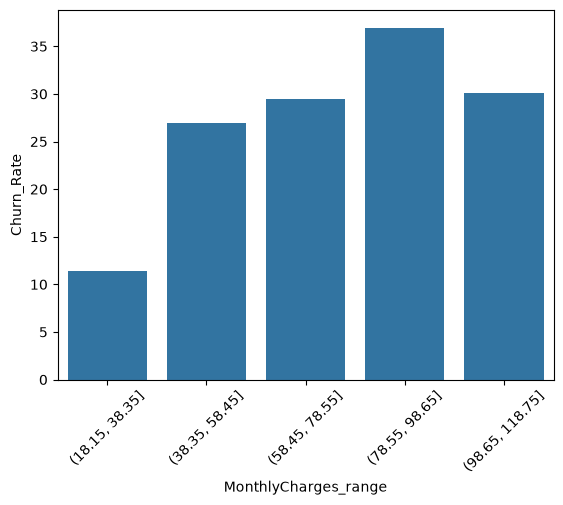

In [21]:
sns.barplot(
    data=churn_monthly,
    x='MonthlyCharges_range',
    y='Churn_Rate'
)

plt.xticks(rotation=45)

In [22]:
pd.crosstab(df['Contract'], df['Churn'], normalize='index')

Churn,No,Yes
Contract,,
Month-to-month,0.572903,0.427097
One year,0.887305,0.112695
Two year,0.971681,0.028319


In [23]:
pd.crosstab(df['InternetService'], df['Churn'], normalize='index')

Churn,No,Yes
InternetService,,
DSL,0.810409,0.189591
Fiber optic,0.581072,0.418928
No,0.925950,0.074050


In [26]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [27]:
df.groupby('Churn')[['tenure','MonthlyCharges','TotalCharges']].median()

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.425,1683.60
Yes,10.0,79.650,703.55


#### Model Training

In [ ]:
#Definição do X e o y
#Definição do X_train, X_test, y_train, y_test
#